# Критерий Уэлча и моделирование мощности

Учебная работа Т-Академии: реализация статистики и p-value, сравнение с SciPy, A/A-проверка и исследование мощности. Данные генерируются в ноутбуке с фиксированным seed.

In [1]:
import numpy as np
from scipy.stats import ttest_ind, t
import matplotlib.pyplot as plt

## 1. Реализация t-статистики

In [2]:
def welch_statistic(a, b):
    a = np.asarray(a, dtype=float)
    b = np.asarray(b, dtype=float)
    if a.ndim == 0 or b.ndim == 0 or a.shape[-1] < 2 or b.shape[-1] < 2:
        raise ValueError("В каждой выборке должно быть не менее двух наблюдений")
    variance_a = a.var(axis=-1, ddof=1)
    variance_b = b.var(axis=-1, ddof=1)
    standard_error = np.sqrt(variance_a / a.shape[-1] + variance_b / b.shape[-1])
    return (a.mean(axis=-1) - b.mean(axis=-1)) / standard_error

## 2. Распределение статистики

Сравниваются одинаковые равномерные распределения и нормальные распределения с различными средними и дисперсиями.

Среднее t для равномерных выборок: -0.0002
Среднее t для нормальных выборок: 1.6053


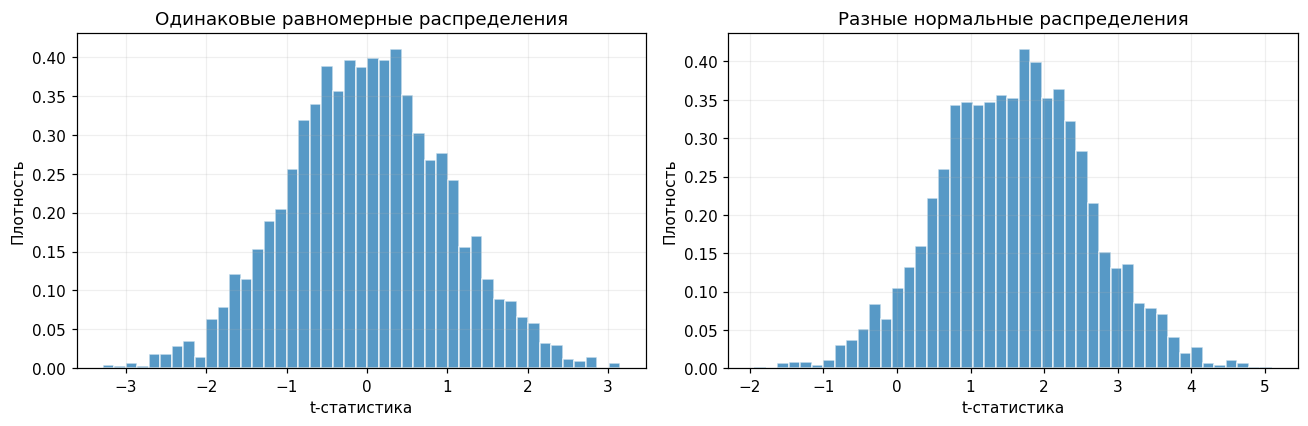

In [3]:
rng = np.random.default_rng(42)
sample_size = 10000
repetitions = 3000


def simulate_statistics(distribution, sample_size, repetitions):
    statistics = np.empty(repetitions)
    for start in range(0, repetitions, 100):
        stop = min(start + 100, repetitions)
        shape = (stop - start, sample_size)
        if distribution == "uniform":
            sample_a = rng.uniform(400, 2000, size=shape)
            sample_b = rng.uniform(400, 2000, size=shape)
        elif distribution == "normal":
            sample_a = rng.normal(1210, 500, size=shape)
            sample_b = rng.normal(1200, 350, size=shape)
        else:
            raise ValueError("Неизвестное распределение")
        statistics[start:stop] = welch_statistic(sample_a, sample_b)
    return statistics


uniform_statistics = simulate_statistics("uniform", sample_size, repetitions)
normal_statistics = simulate_statistics("normal", sample_size, repetitions)
uniform_a = rng.uniform(400, 2000, sample_size)
uniform_b = rng.uniform(400, 2000, sample_size)
normal_a = rng.normal(1210, 500, sample_size)
normal_b = rng.normal(1200, 350, sample_size)

figure, axes = plt.subplots(1, 2, figsize=(12, 4))
for axis, statistics, title in zip(
    axes,
    [uniform_statistics, normal_statistics],
    ["Одинаковые равномерные распределения", "Разные нормальные распределения"]
):
    axis.hist(statistics, bins=45, density=True, alpha=0.75, edgecolor="white")
    axis.set(title=title, xlabel="t-статистика", ylabel="Плотность")
    axis.grid(alpha=0.2)
plt.tight_layout()
plt.show()

print(f"Среднее t для равномерных выборок: {uniform_statistics.mean():.4f}")
print(f"Среднее t для нормальных выборок: {normal_statistics.mean():.4f}")

## 3. Изменение размера выборки

Для одинаковых распределений сравнивается эмпирическая t-статистика с N(0, 1).

n = 50: среднее = -0.0088, дисперсия = 1.0000
n = 1000: среднее = 0.0071, дисперсия = 1.0427
n = 10000: среднее = -0.0002, дисперсия = 0.9713


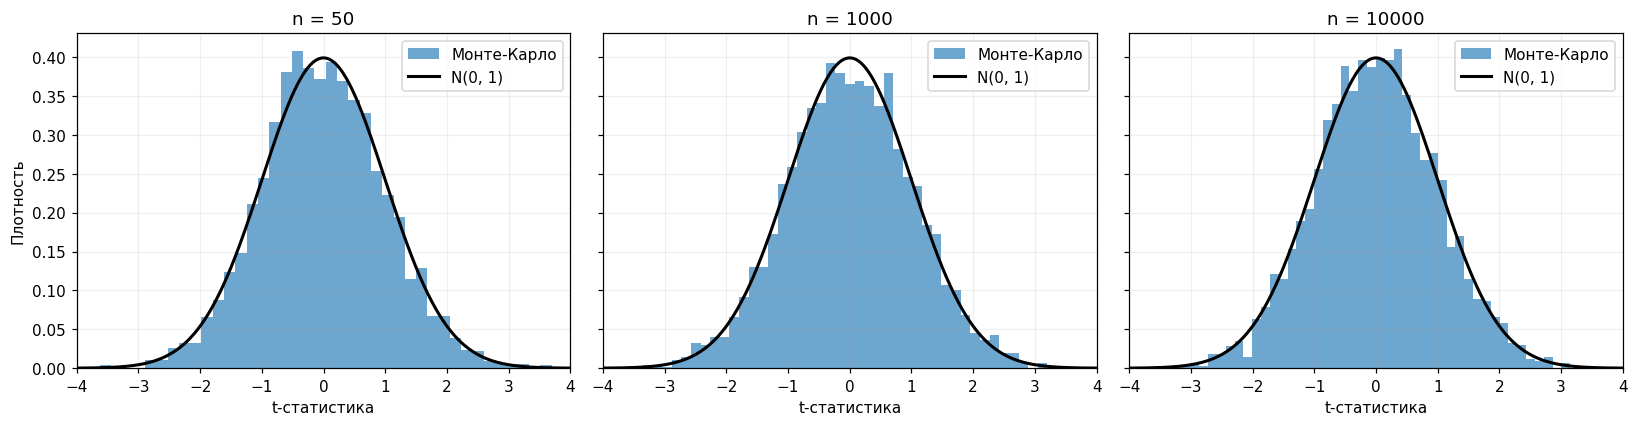

In [4]:
sample_sizes = [50, 1000, 10000]
grid = np.linspace(-4, 4, 500)
normal_density = np.exp(-grid ** 2 / 2) / np.sqrt(2 * np.pi)
figure, axes = plt.subplots(1, 3, figsize=(15, 4), sharex=True, sharey=True)

for axis, size in zip(axes, sample_sizes):
    statistics = uniform_statistics if size == 10000 else simulate_statistics("uniform", size, repetitions)
    axis.hist(statistics, bins=45, density=True, alpha=0.65, label="Монте-Карло")
    axis.plot(grid, normal_density, color="black", linewidth=2, label="N(0, 1)")
    axis.set(title=f"n = {size}", xlabel="t-статистика", xlim=(-4, 4))
    axis.grid(alpha=0.2)
    axis.legend()
    print(f"n = {size}: среднее = {statistics.mean():.4f}, дисперсия = {statistics.var(ddof=1):.4f}")
axes[0].set_ylabel("Плотность")
plt.tight_layout()
plt.show()

## 4. Двустороннее p-value

Степени свободы рассчитываются по приближению Уэлча — Саттертуэйта.

In [5]:
def welch_test(a, b):
    a = np.asarray(a, dtype=float)
    b = np.asarray(b, dtype=float)
    statistic = welch_statistic(a, b)
    size_a = a.shape[-1]
    size_b = b.shape[-1]
    term_a = a.var(axis=-1, ddof=1) / size_a
    term_b = b.var(axis=-1, ddof=1) / size_b
    degrees = (term_a + term_b) ** 2 / (
        term_a ** 2 / (size_a - 1) + term_b ** 2 / (size_b - 1)
    )
    pvalue = 2 * t.sf(np.abs(statistic), df=degrees)
    return statistic, pvalue


statistic, pvalue = welch_test(normal_a, normal_b)
print(f"t-статистика: {statistic:.6f}")
print(f"Двустороннее p-value: {pvalue:.6f}")
print("H₀ отвергается при α = 0.05" if pvalue < 0.05 else "Нет оснований отвергать H₀ при α = 0.05")

t-статистика: 1.623565
Двустороннее p-value: 0.104486
Нет оснований отвергать H₀ при α = 0.05


## 5. Сравнение с SciPy и A/A

Своя реализация сопоставляется с ttest_ind(equal_var=False). В серии A/A оценивается доля ложных отклонений нулевой гипотезы.

Равномерные выборки
Своя функция: t = 0.6683504818, p = 0.5039176104
scipy:        t = 0.6683504818, p = 0.5039176104
Результаты совпадают: True
Нормальные выборки
Своя функция: t = 1.6235651340, p = 0.1044863015
scipy:        t = 1.6235651340, p = 0.1044863015
Результаты совпадают: True
Среднее p-value: 0.4903
Доля ложных отклонений H₀ при α = 0.05: 0.0570


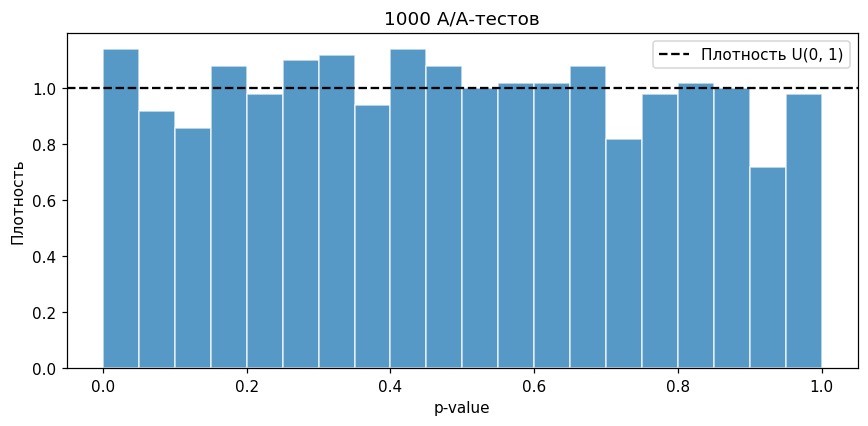

In [6]:
for title, sample_a, sample_b in [
    ("Равномерные выборки", uniform_a, uniform_b),
    ("Нормальные выборки", normal_a, normal_b)
]:
    statistic, pvalue = welch_test(sample_a, sample_b)
    scipy_result = ttest_ind(sample_a, sample_b, equal_var=False)
    print(title)
    print(f"Своя функция: t = {statistic:.10f}, p = {pvalue:.10f}")
    print(f"scipy:        t = {scipy_result.statistic:.10f}, p = {scipy_result.pvalue:.10f}")
    print(f"Результаты совпадают: {np.allclose([statistic, pvalue], scipy_result[:2])}")

test_count = 1000
pvalues = np.empty(test_count)
for start in range(0, test_count, 100):
    stop = min(start + 100, test_count)
    sample_a = rng.uniform(400, 2000, size=(stop - start, sample_size))
    sample_b = rng.uniform(400, 2000, size=(stop - start, sample_size))
    statistics, pvalues[start:stop] = welch_test(sample_a, sample_b)

plt.figure(figsize=(8, 4))
plt.hist(pvalues, bins=np.linspace(0, 1, 21), density=True, alpha=0.75, edgecolor="white")
plt.axhline(1, color="black", linestyle="--", label="Плотность U(0, 1)")
plt.xlabel("p-value")
plt.ylabel("Плотность")
plt.title("1000 А/А-тестов")
plt.legend()
plt.tight_layout()
plt.show()
print(f"Среднее p-value: {pvalues.mean():.4f}")
print(f"Доля ложных отклонений H₀ при α = 0.05: {(pvalues < 0.05).mean():.4f}")

## 6. Кривые мощности

Для n = 50, 1 000 и 10 000 исследуется вероятность обнаружить заданное относительное изменение среднего.

Изменение, % | n = 50 | n = 1000 | n = 10000
         0.0 | 0.063 | 0.048 | 0.044
         0.5 | 0.051 | 0.061 | 0.169
         1.0 | 0.051 | 0.117 | 0.584
         1.5 | 0.049 | 0.179 | 0.900
         2.0 | 0.083 | 0.266 | 0.993
         2.5 | 0.065 | 0.407 | 0.999
         3.0 | 0.069 | 0.504 | 1.000
         3.5 | 0.087 | 0.678 | 1.000
         4.0 | 0.094 | 0.775 | 1.000
         4.5 | 0.096 | 0.861 | 1.000
         5.0 | 0.122 | 0.921 | 1.000


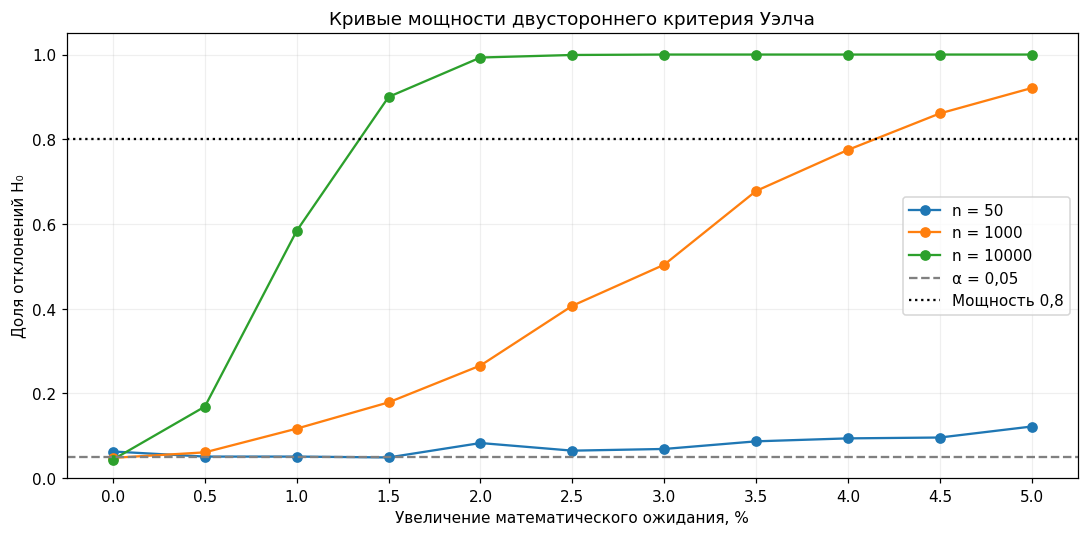

In [7]:
alpha = 0.05
mean = 1200
sigma = 400
power_repetitions = 1000
changes = np.arange(0, 5.5, 0.5)
power_curves = {}
plt.figure(figsize=(10, 5))

for size in sample_sizes:
    power = np.empty(changes.size)
    for index, change in enumerate(changes):
        rejected = 0
        for start in range(0, power_repetitions, 100):
            count = min(100, power_repetitions - start)
            sample_a = rng.normal(mean, sigma, size=(count, size))
            sample_b = rng.normal(mean * (1 + change / 100), sigma, size=(count, size))
            statistics, pvalues = welch_test(sample_a, sample_b)
            rejected += np.count_nonzero(pvalues < alpha)
        power[index] = rejected / power_repetitions
    power_curves[size] = power
    plt.plot(changes, power, marker="o", label=f"n = {size}")

plt.axhline(alpha, color="gray", linestyle="--", label="α = 0,05")
plt.axhline(0.8, color="black", linestyle=":", label="Мощность 0,8")
plt.xlabel("Увеличение математического ожидания, %")
plt.ylabel("Доля отклонений H₀")
plt.title("Кривые мощности двустороннего критерия Уэлча")
plt.xticks(changes)
plt.ylim(0, 1.05)
plt.grid(alpha=0.2)
plt.legend()
plt.tight_layout()
plt.show()

print("Изменение, % | " + " | ".join(f"n = {size}" for size in sample_sizes))
for index, change in enumerate(changes):
    print(f"{change:12.1f} | " + " | ".join(f"{power_curves[size][index]:.3f}" for size in sample_sizes))

## Ограничения

Результаты относятся к независимым синтетическим выборкам. Частота по конечному числу повторов имеет Monte Carlo-погрешность; она не является точным теоретическим значением мощности. Размер выборки, величина эффекта и дисперсия влияют на мощность. Просмотр промежуточных p-value и досрочная остановка в этом кейсе не моделируются.